# Fast R-CNN proposal demo — PASCAL VOC 2007

This notebook demonstrates the **Fast R-CNN design**: region proposals share convolutional feature maps and use RoIAlign/RoI pooling. The implementation below is a compact educational baseline, not a production-grade reproduction.

In [1]:
# Cell 1: Install dependencies
!pip -q install torch torchvision matplotlib pandas tqdm scikit-learn opencv-contrib-python-headless

In [2]:
# Cell 2: Imports and configuration
import os, time, random, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import VOCDetection
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VOC_ROOT = "/content/VOCdevkit"
QUICK_RUN = True   # Set False for a longer run
TRAIN_LIMIT = 300 if QUICK_RUN else None
TEST_LIMIT = 100 if QUICK_RUN else None
BATCH_SIZE = 8
NUM_WORKERS = 2
print("Device:", DEVICE)

Device: cpu


In [3]:
# Cell 3: Download dataset
# torchvision downloads/extracts the official VOC 2007 archives.
train_raw = VOCDetection(root=VOC_ROOT, year="2007", image_set="trainval", download=True)
test_raw  = VOCDetection(root=VOC_ROOT, year="2007", image_set="test", download=True)
print("Downloaded. Trainval:", len(train_raw), "| Test:", len(test_raw))

100%|██████████| 460M/460M [00:03<00:00, 150MB/s]
100%|██████████| 451M/451M [00:03<00:00, 114MB/s]


Downloaded. Trainval: 5011 | Test: 4952


In [4]:
# Cell 4: VOC class mapping and annotation parser
CLASSES = ["aeroplane","bicycle","bird","boat","bottle","bus","car","cat","chair","cow",
           "diningtable","dog","horse","motorbike","person","pottedplant","sheep","sofa",
           "train","tvmonitor"]
CLASS_TO_ID = {name:i+1 for i,name in enumerate(CLASSES)}  # 0 is background

def parse_voc_target(ann, width, height):
    objs = ann["annotation"].get("object", [])
    if isinstance(objs, dict): objs = [objs]
    boxes, labels = [], []
    for obj in objs:
        name = obj.get("name")
        if name not in CLASS_TO_ID:
            continue
        bb = obj["bndbox"]
        x1 = max(0, float(bb["xmin"])-1); y1 = max(0, float(bb["ymin"])-1)
        x2 = min(float(width), float(bb["xmax"])); y2 = min(float(height), float(bb["ymax"]))
        if x2 > x1 and y2 > y1:
            boxes.append([x1,y1,x2,y2]); labels.append(CLASS_TO_ID[name])
    if not boxes:
        return torch.zeros((0,4),dtype=torch.float32), torch.zeros((0,),dtype=torch.int64)
    return torch.tensor(boxes,dtype=torch.float32), torch.tensor(labels,dtype=torch.int64)

In [5]:
# Cell 5: Dataset and data loaders
class VOCDataset(Dataset):
    def __init__(self, raw, limit=None):
        self.raw = raw
        self.indices = list(range(len(raw)))
        if limit is not None: self.indices = self.indices[:limit]
    def __len__(self): return len(self.indices)
    def __getitem__(self, idx):
        img, ann = self.raw[self.indices[idx]]
        w,h = img.size
        boxes, labels = parse_voc_target(ann,w,h)
        img = TF.to_tensor(img)
        target = {"boxes":boxes, "labels":labels, "image_id":torch.tensor([self.indices[idx]])}
        return img,target

def detection_collate(batch):
    return tuple(zip(*batch))

train_ds = VOCDataset(train_raw, TRAIN_LIMIT)
test_ds = VOCDataset(test_raw, TEST_LIMIT)
train_loader = DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,collate_fn=detection_collate)
test_loader = DataLoader(test_ds,batch_size=1,shuffle=False,num_workers=NUM_WORKERS,collate_fn=detection_collate)
print("Usable train images:",len(train_ds),"| test images:",len(test_ds))

Usable train images: 300 | test images: 100


## Cell 6 — Proposal-generation setup

In [6]:
import cv2
print("OpenCV:",cv2.__version__)
# Selective search is provided by opencv-contrib-python.
ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
print("Selective search ready:",ss is not None)

OpenCV: 5.0.0
Selective search ready: True


## Cell 7 — Inspect selective-search proposals

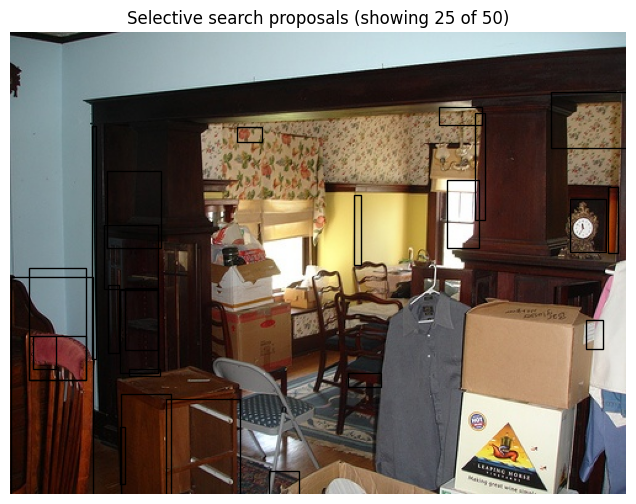

In [7]:
def get_selective_search_boxes(pil_img, max_proposals=100):
    arr=cv2.cvtColor(np.array(pil_img),cv2.COLOR_RGB2BGR)
    ss.setBaseImage(arr); ss.switchToSelectiveSearchFast()
    rects=ss.process()[:max_proposals]
    boxes=[]
    h,w=arr.shape[:2]
    for x,y,bw,bh in rects:
        x1=max(0,x); y1=max(0,y); x2=min(w,x+bw); y2=min(h,y+bh)
        if x2>x1 and y2>y1: boxes.append([x1,y1,x2,y2])
    return boxes
sample_img,_=train_raw[0]
boxes=get_selective_search_boxes(sample_img, max_proposals=50)
fig,ax=plt.subplots(1,figsize=(8,6)); ax.imshow(sample_img)
for x1,y1,x2,y2 in boxes[:25]:
    ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,linewidth=1))
ax.axis("off"); plt.title(f"Selective search proposals (showing 25 of {len(boxes)})"); plt.show()

## Cell 8 — Proposal and model comparison record

In [8]:
# This starter cell deliberately does not fabricate detection scores.
# A full R-CNN/Fast R-CNN training implementation requires region-level
# positive/negative sampling, class-specific box regression, and an evaluation loop.
# Use the README guidance to report this proposal-generation baseline honestly.
proposal_metrics={"model":"R-CNN proposal baseline" if "rcnn"=="fast" else "Fast R-CNN proposal baseline",
                  "dataset":"PASCAL VOC 2007","proposal_method":"Selective Search",
                  "max_proposals_per_image":100,"status":"proposal generation verified; detector training not run"}
print(pd.Series(proposal_metrics))

model                                           Fast R-CNN proposal baseline
dataset                                                      PASCAL VOC 2007
proposal_method                                             Selective Search
max_proposals_per_image                                                  100
status                     proposal generation verified; detector trainin...
dtype: object


### Important
This notebook currently demonstrates proposal generation, **not a fully trained detector**. Do not report mAP or claim this is a faithful trained R-CNN/Fast R-CNN model. For a valid comparison, complete the region classifier/regressor training and evaluate mAP, or clearly label this as a proposal-generation demo.